<a href="https://colab.research.google.com/github/tranduchoa518-lang/fake-news-detection/blob/main/notebooks/04_naive_bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Đã import thư viện thành công!")

Đã import thư viện thành công!


In [3]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Tên file:", filename)
print("Kích thước dữ liệu:", df.shape)
print("Các cột:", df.columns.tolist())

df.head()


Saving preprocessed_fake_news.csv to preprocessed_fake_news.csv
Kích thước dữ liệu: (300, 7)


In [4]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_tfidf = tfidf.fit_transform(X)

print("Kích thước ma trận TF-IDF:", X_tfidf.shape)

Kích thước ma trận TF-IDF: (300, 1101)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Số mẫu huấn luyện:", X_train.shape[0])
print("Số mẫu kiểm tra:", X_test.shape[0])

Số mẫu huấn luyện: 240
Số mẫu kiểm tra: 60


In [6]:
model = MultinomialNB()

model.fit(X_train, y_train)

print("Huấn luyện Naive Bayes hoàn tất!")

Huấn luyện Naive Bayes hoàn tất!


In [7]:
y_pred = model.predict(X_test)

print("Dự đoán hoàn tất!")

Dự đoán hoàn tất!


In [8]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("KẾT QUẢ ĐÁNH GIÁ NAIVE BAYES")
print("--------------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

KẾT QUẢ ĐÁNH GIÁ NAIVE BAYES
--------------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0


In [9]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Tin giả", "Tin thật"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Tin giả       1.00      1.00      1.00        30
    Tin thật       1.00      1.00      1.00        30

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



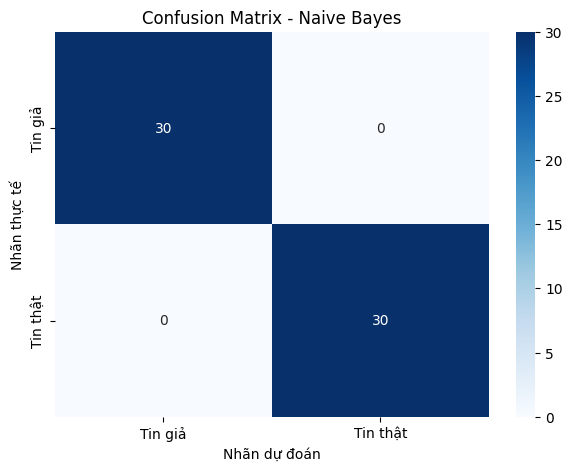

In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Tin giả", "Tin thật"],
    yticklabels=["Tin giả", "Tin thật"]
)

plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")

plt.show()

In [12]:

import re
import string

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

print(preprocess_text("FAKE NEWS - Example 123!"))


fake news example


In [13]:
def predict_fake_news(news):

    clean_news = preprocess_text(news)

    news_vector = tfidf.transform([clean_news])

    prediction = model.predict(news_vector)[0]

    if prediction == 1:
        return "Dự đoán: TIN THẬT"
    else:
        return "Dự đoán: TIN GIẢ"


sample_news = """
The government announced a new policy to improve education.
"""

print(predict_fake_news(sample_news))

Dự đoán: TIN GIẢ
